In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
data = pd.read_csv("/content/marketing_campaign.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
# Reload the data using tab separator since 'marketing_campaign.csv' is tab-separated
data = pd.read_csv("/content/marketing_campaign.csv", sep='\t')

# Map the education column to numeric values
data['Education'] = data['Education'].map({
    'Basic': 0,
    '2n Cycle': 1,
    'Graduation': 2,
    'Master': 3,
    'PhD': 4
})

data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,2,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,2,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,2,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,2,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,4,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [ ]:
X = data[['Income', 'MntWines']]

print("Features selected for clustering: Income and Wine Spending")

X.head()

Features selected for clustering: Income and Wine Spending


,Income,MntWines
0,58138.0,635
1,46344.0,11
2,71613.0,426
3,26646.0,11
4,58293.0,173


In [ ]:
# Apply StandardScaler to normalize the selected features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature scaling complete using StandardScaler")

Feature scaling complete using StandardScaler


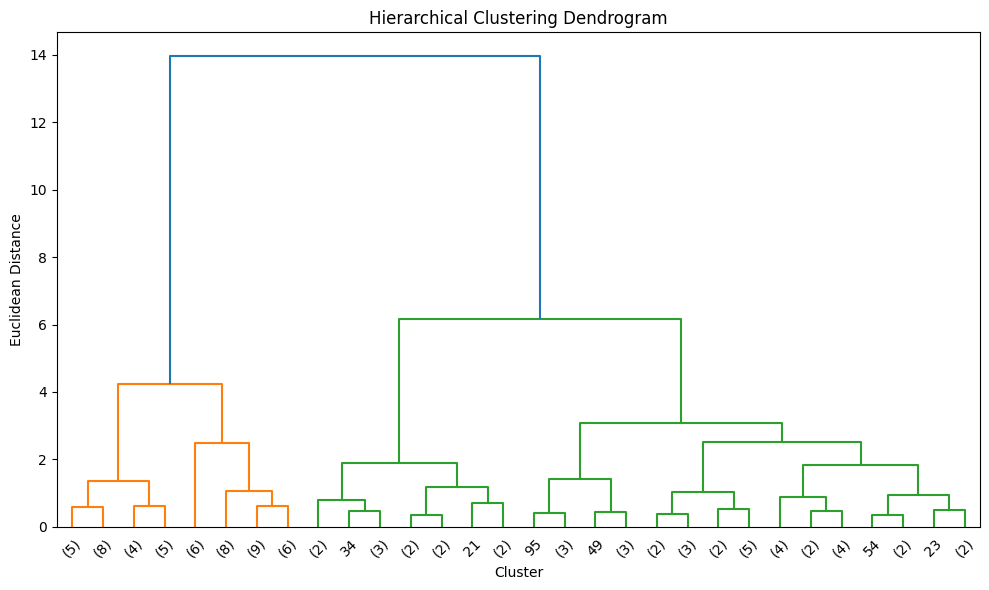

In [ ]:
# Plot a clearer dendrogram after handling missing values
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Drop rows containing missing values from selected features first
X_clean = X.dropna()

# Re-scale the clean features
scaler = StandardScaler()
X_scaled_clean = scaler.fit_transform(X_clean)

# Select the first 100 customers from the clean scaled dataset
X_sample = X_scaled_clean[:100]

# Perform hierarchical clustering using Ward linkage
linked = linkage(X_sample, method='ward', metric='euclidean')

plt.figure(figsize=(10, 6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster')
plt.ylabel('Euclidean Distance')
plt.tight_layout()
plt.show()